# Load modules 

In [45]:
from pathlib import Path
import sys
import importlib
import math

import anndata as an
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import squidpy as sq
from matplotlib.patches import Patch

plt.rcdefaults()

code_dir = "/projects/Pregnancy_placenta/Code_Publication/Python/"
HELPER_FUNCS_DIR = Path(code_dir) / "Functions"
TMA_PATH = Path(
    "/home/plopez/orcd/pool/Projects/Preg_placenta_VISIUM/data/Final_Objs/final_TMA_obj_V2.h5ad"
)
FINAL_FIG_DIR = Path(
    "/home/plopez/orcd/pool/Projects/Preg_placenta_VISIUM/results/final_figures/Figure_1"
)
SCALE_BAR_UM = 100


## load functions 

In [46]:
if str(HELPER_FUNCS_DIR) not in sys.path:
    sys.path.append(str(HELPER_FUNCS_DIR))

import vis_tcell_helpful_func as vis_tcr_plt
importlib.reload(vis_tcr_plt)

import visium_plotting as vis_plt
importlib.reload(vis_plt)   # if you edit it and want to refresh

vis_plt.configure_publication_fonts()


# load obj 

In [7]:
TMA_obj = an.read_h5ad(TMA_PATH)


# Figure 1H (left)

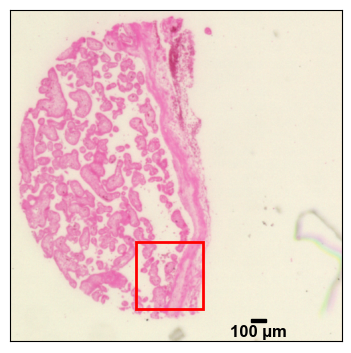

In [47]:
rect_box = (470, 1250, 570, 1350)
lib = "TMA2-140"
scale_bar_px = vis_plt.get_scale_bar_px(TMA_obj[TMA_obj.obs["library_id"] == lib].copy(), scale_bar_um=SCALE_BAR_UM)

fig, ax, crop = vis_plt.plot_tma_crop_or_rect(
    TMA_obj,
    zoom_rect=rect_box,
    img=True,
    size=1,
    shape="square",
    library_id=lib,
    orientation="top_left",
    title=None,
)

vis_plt.add_scale_bar(
    ax,
    scale_bar_px,
    label=f"{SCALE_BAR_UM} µm",
    pad=0.2,
    bbox_to_anchor=(0.85, -0.01),
    bbox_transform=ax.transAxes,
    size_vertical=4,
)
ax.set_title("")
vis_plt.clean_spatial_axis(ax, "", fontsize=20)

vis_plt.save_figure(
    fig,
    "Fig1H_histology_example_TMA2-140_V2.pdf",
    FINAL_FIG_DIR,
    format="pdf",
    dpi=600,
    pad_inches=0.1,
)

# Figure 1H (middle)


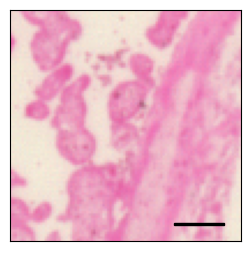

In [32]:
crop = (470, 1250, 570, 1350)
lib = "TMA2-140"
scale_bar_px = vis_plt.get_scale_bar_px(TMA_obj[TMA_obj.obs["library_id"] == lib].copy(), scale_bar_um=SCALE_BAR_UM)

fig, ax = plt.subplots(figsize=(3, 3))

sq.pl.spatial_scatter(
    TMA_obj,
    img=True,
    library_key="library_id",
    library_id=lib,
    shape="square",
    cmap="YlOrRd",
    alpha=0.8,
    size=1,
    outline=False,
    crop_coord=crop,
    legend_loc=None,
    colorbar=False,
    ax=ax,
)

vis_plt.add_scale_bar(
    ax,
    scale_bar_px,
    bbox_to_anchor=(0.95, -0.03),
    bbox_transform=ax.transAxes,
    size_vertical=0.7,
)
vis_plt.clean_spatial_axis(ax, "", fontsize=20)
vis_plt.save_figure(
    fig,
    "Fig1H_histology_example_ZOOMED-IN_TMA2-140_V2.pdf",
    FINAL_FIG_DIR,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.01,
)


# Figure 1H (right)

In [31]:
crop = (470, 1250, 570, 1350)
lib = "TMA2-140"
scale_bar_px = vis_plt.get_scale_bar_px(TMA_obj[TMA_obj.obs["library_id"] == lib].copy(), scale_bar_um=SCALE_BAR_UM)

fig, ax = plt.subplots(figsize=(3, 3))

sq.pl.spatial_scatter(
    TMA_obj,
    img=True,
    library_key="library_id",
    library_id=lib,
    shape="square",
    cmap="YlOrRd",
    color="dominant_parent_type",
    alpha=0.8,
    size=1,
    outline=False,
    crop_coord=crop,
    legend_loc=None,
    colorbar=False,
    ax=ax,
)

vis_plt.add_scale_bar(
    ax,
    scale_bar_px,
    bbox_to_anchor=(0.95, -0.03),
    bbox_transform=ax.transAxes,
    size_vertical=0.8,
)
vis_plt.clean_spatial_axis(ax, "", fontsize=20)
vis_plt.save_figure(
    fig,
    "Fig1H_dominant_parent_zoom_example_TMA2-140_V2.pdf",
    FINAL_FIG_DIR,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.01,
)


# Figure 1I 

In [39]:
color_order = ["Villous trophoblasts", "fFB", "HBC", "EVT", "dS", "mMac"]
crop = (470, 1250, 570, 1350)
lib = "TMA2-140"
scale_bar_px = vis_plt.get_scale_bar_px(TMA_obj[TMA_obj.obs["library_id"] == lib].copy(), scale_bar_um=SCALE_BAR_UM)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(24, 15),
    gridspec_kw={"wspace": 0.02, "hspace": 0.1},
)
axes = axes.ravel()

for indx, color in enumerate(color_order):
    sq.pl.spatial_scatter(
        TMA_obj,
        color=[color],
        img=True,
        library_key="library_id",
        library_id=lib,
        shape="square",
        cmap="YlOrRd",
        alpha=0.8,
        size=1,
        outline=False,
        crop_coord=crop,
        ax=axes[indx],
        legend_loc=None,
        colorbar=False,
    )

    vis_plt.add_scale_bar(
        axes[indx],
        scale_bar_px,
        bbox_to_anchor=(0.95, -0.01),
        bbox_transform=axes[indx].transAxes,
        size_vertical=0.7,
    )
    vis_plt.clean_spatial_axis(axes[indx], color, fontsize=36, pad=4)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.95,
    bottom=0.03,
    wspace=0.04,
    hspace=0.22,
)

vis_plt.save_figure(
    fig,
    "Fig1I_dominant_parent_zoom_example_TMA2-140_C2l_results_V3.pdf",
    FINAL_FIG_DIR,
    format="pdf",
    dpi=600,
    bbox_inches="tight",
)
plt.close(fig)


# Legends

## Figure 1H 

(0.0, 1.0, 0.0, 1.0)

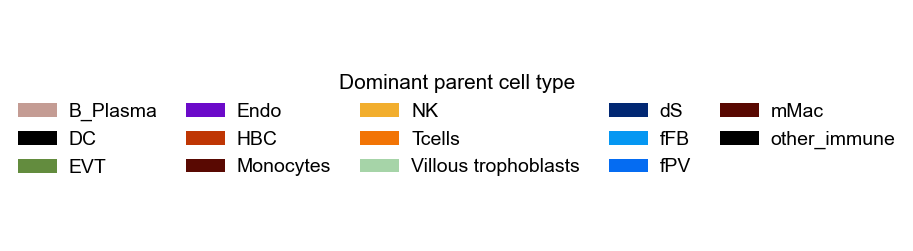

In [42]:
eliminate = {"VCT", "VCTccc", "VCTfusion", "VCTp", "mixed_HBC"}
rename_map = {"SCT": "Villous Trophoblasts"}

cats = list(TMA_obj.obs["dominant_parent_type"].cat.categories)
cols = list(TMA_obj.uns["dominant_parent_type_colors"])

pairs = []
for cat, col in zip(cats, cols):
    if cat in eliminate:
        continue
    label = rename_map.get(cat, cat)
    pairs.append((label, col))

handles = [Patch(facecolor=color, edgecolor="none", label=label) for label, color in pairs]

n_rows = 3
ncol = int(np.ceil(len(handles) / n_rows))

fig, ax = plt.subplots(figsize=(7, 3))
ax.legend(
    handles=handles,
    title="Dominant parent cell type",
    ncol=ncol,
    loc="center",
    frameon=False,
    fontsize=14,
    title_fontsize=15,
    columnspacing=1.5,
    handletextpad=0.6,
)
ax.axis("off")

vis_plt.save_figure(
    fig,
    "Fig1H_dominant_parent_legend_filtered_5rows.pdf",
    FINAL_FIG_DIR,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.1,
)
plt.close(fig)


## Figure 1I legend

In [ ]:
fig, ax = plt.subplots(figsize=(5, 1.2))

norm = mpl.colors.Normalize(vmin=0, vmax=1)
cmap = mpl.cm.YlOrRd

cb = mpl.colorbar.ColorbarBase(
    ax,
    cmap=cmap,
    norm=norm,
    orientation="horizontal",
)

cb.set_label("Cell-type proportion per bin\n(fraction of total cells)", fontsize=14)
cb.ax.tick_params(labelsize=12)

plt.tight_layout()
vis_plt.save_figure(
    fig,
    "Fig1h_colorbar_cell_type_proportion_option1_V1.pdf",
    FINAL_FIG_DIR,
    format="pdf",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1,
)
